# 06 · Phase 2 Brief, the Deep-Learning Dataset and Ordered Delay Histories
**Owner:** Balanagu Sesha Srikar (2401010124) · Phase 2 rubric: **DL dataset**, **architecture logic (inputs)**, **technical validation (leakage)**

**Builds on:** Phase 1 notebooks 01–05 (same data, label, 05:00 decision time, split and 41 features).
**Commits:** `src/fdp/dl_inputs.py`, `tests/test_leakage.py` (one new test), `reports/06_dl_data.json`, `reports/figures/06_*.png`.

| Section | What it answers |
|---|---|
| A · What Phase 2 asks for | the brief, and the gap Phase 1 left |
| B · What a network can read at 05:00 | numeric block, category indices, sequences |
| C · Ordered delay histories | building the 14-day sequences, and proving they do not leak |
| D · Why "relative" history | the drift Phase 1 found, measured on the inputs |

⏱️ About 2 minutes on a Colab CPU.

In [1]:
#@title ⚙️ 0 · Setup — run this cell first { display-mode: "form" }
#@markdown In **Colab** this clones the team repo and installs the requirements.
#@markdown Locally (Jupyter / VS Code) it just moves to the repo root.
REPO_URL = "https://github.com/mrstrange1708/T107_Flight_Delay_Prediction.git"  #@param {type:"string"}
BRANCH = "main"  #@param {type:"string"}
QUICK_RUN = False  #@param {type:"boolean"}
#@markdown `QUICK_RUN` = smaller searches/samples so the notebook finishes in a few minutes (use it to check the code runs; turn it OFF for the final numbers you commit).

import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.isdir("/content/aml-project/.git"):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, "/content/aml-project"], check=True)
    os.chdir("/content/aml-project")
    if os.path.exists("requirements.txt"):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
for d in ["src/fdp", "tests", "data/raw", "data/processed", "reports/figures"]:
    os.makedirs(d, exist_ok=True)
open("src/fdp/__init__.py", "a").close()
sys.path.insert(0, os.path.abspath("src"))

import warnings; warnings.filterwarnings("ignore")
import torch; torch.set_num_threads(max(1, os.cpu_count() or 1))
import json, importlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Working directory:", os.getcwd(), "| Colab:", IN_COLAB, "| QUICK_RUN:", QUICK_RUN)

Working directory: /tmp/fdp | Colab: False | QUICK_RUN: False


In [2]:
import fdp.config as config, fdp.data as data, fdp.features as features
df = data.build_dataset(*data.load_raw())
X, groups = features.build_features(df)
NUM, CAT = features.numeric_columns(groups), config.CATEGORICAL
S = data.split(X)
print({k: len(v) for k, v in S.items()})

{'train': 205642, 'valid': 27010, 'calib': 28618, 'test': 53991}


---
## A · What Phase 2 asks for
**Project 21 (Phase 2 part):** *Operational tabular features → learned temporal and route patterns.*
* **Identify the gap:** manual route and congestion summaries may miss interactions between time, airport, carrier and recent delay dynamics.
* **DL model:** a compact MLP with **learned embeddings** for airline, origin and destination. A **temporal model** is optional, *only if flight history is correctly ordered*.
* **Fair comparison:** split by date; report PR AUC, ROC AUC, **recall at an operational precision threshold** and **calibration**; compare only features available at the decision time.
* **Deliverable:** a delay-risk model with **calibrated probabilities** and an **offline what-if rescheduling analysis** with explicit assumptions.

**Where Phase 1 left us** (from the Phase 1 report, test months Nov–Dec, scored once): logistic regression 0.403, tuned XGBoost 0.390, hybrid (boosting from LR) 0.403; intervals about ±0.05 wide, so **no clear winner**. Phase 1's own explanation, and the gap Phase 2 attacks:
1. the 1/7/28-day history averages are **hand-made summaries**: they fix the window and throw away the order of days;
2. those averages are **absolute levels** that drift between summer and autumn;
3. one-hot categories treat 100 destinations as unrelated; **embeddings** can learn which airports behave alike.

**Nothing about the setup changes:** same label (arrives ≥ 15 min late), same 05:00 decision time, same chronological split, test months still scored **once** (notebook 10).

---
## B · What a network can read at 05:00
A neural network needs three kinds of input, all built from the **same** 05:00 information as Phase 1:

| Block | Shape | How it is prepared (fitted on training rows only) |
|---|---|---|
| numeric | 41 features + 1 "aircraft data missing" flag | median imputation, then z-score (networks train badly when inputs have very different scales) |
| categories | carrier, origin, dest as integer **indices** | index 0 = never seen in training, 1 = seen fewer than 50 times, 2… = one per common category |
| sequence (temporal model only) | 14 past days × 16 channels | see section C |

The index is **not** a number the network does arithmetic on: it selects a row of an **embedding table**, a small vector of weights learned during training (notebook 07).

In [3]:
%%writefile src/fdp/dl_inputs.py
"""Phase 2 · everything a network reads at 05:00.
Owner: Balanagu Sesha Srikar (Srikar).

Part 1 - tabular inputs: TabularEncoder turns the 41 Phase 1 features and the 3 categories into
arrays (numeric block, category indices for the embedding tables).

Part 2 - ordered delay histories for the temporal model:

For a flight on day D the temporal model reads the LAST L DAYS (D-L ... D-1) of delay outcomes
for the groups the flight belongs to (all flights, its origin, carrier, carrier at origin, route,
flight number, aircraft). Phase 1 squeezed these days into a few hand-made averages (1/7/28-day
rates); here the network sees the whole ordered sequence and learns how to weigh the days.

Leakage rule (same as Phase 1): the window ends on day D-1. Day D's own outcomes are never read.
"""
import numpy as np
import pandas as pd

MISSING_FLAG_COLS = ["plane_age", "plane_seats", "plane_engines"]


class TabularEncoder:
    """Fit on training rows only: medians, means, stds and category vocabularies.

    Categories seen fewer than `min_count` times in training share index 1 ('rare');
    index 0 is reserved for categories never seen in training ('unknown')."""

    def __init__(self, numeric, categorical, min_count: int = 50):
        self.numeric, self.categorical, self.min_count = list(numeric), list(categorical), min_count

    def fit(self, X: pd.DataFrame):
        num = X[self.numeric].astype(float)
        self.median = num.median()
        filled = num.fillna(self.median)
        self.mean, self.std = filled.mean(), filled.std().replace(0, 1.0)
        self.vocab, self.seen = {}, {}
        for c in self.categorical:
            counts = X[c].astype(str).value_counts()
            self.vocab[c] = {v: i + 2 for i, v in enumerate(sorted(counts[counts >= self.min_count].index))}
            self.seen[c] = set(counts.index)
        return self

    def cardinalities(self):
        return [len(self.vocab[c]) + 2 for c in self.categorical]

    def transform(self, X: pd.DataFrame):
        num = X[self.numeric].astype(float)
        flags = num[MISSING_FLAG_COLS].isna().any(axis=1).astype(float).to_numpy()[:, None]
        z = ((num.fillna(self.median) - self.mean) / self.std).to_numpy()
        x_num = np.hstack([z, flags]).astype(np.float32)
        cols = []
        for c in self.categorical:
            s = X[c].astype(str)
            code = s.map(self.vocab[c]).fillna(0).astype(int).to_numpy()
            rare = (code == 0) & s.isin(self.seen[c]).to_numpy()
            cols.append(np.where(rare, 1, code))       # seen but rare -> 1; never seen -> 0
        return x_num, np.stack(cols, axis=1).astype(np.int64)


def emb_dim(n: int) -> int:
    """Rule of thumb for embedding size: grows slowly with the number of categories."""
    return int(min(16, round(1.6 * n ** 0.56)))



# ----------------------------------------------------------------- ordered histories

# (name, grouping columns). "all" is every flight from NYC that day.
SEQ_GROUPS = [
    ("origin", ["origin"]),
    ("carrier", ["carrier"]),
    ("carrier_origin", ["carrier", "origin"]),
    ("route", ["origin", "dest"]),
    ("flight", ["carrier", "flight"]),
    ("tail", ["tailnum"]),
]
SEQ_LEN = 14       # two weeks: the ACF said yesterday matters most, but small groups need more days
SEQ_ALPHA = 5.0    # daily counts are small, so shrink each day's rate towards that day's overall rate


def _key(df, cols):
    k = df[cols[0]].astype(str)
    for c in cols[1:]:
        k = k + "|" + df[c].astype(str)
    return k


def channel_names():
    names = ["all_rate", "all_logn"]
    for name, _ in SEQ_GROUPS:
        names += [f"{name}_rel", f"{name}_logn"]
    return names + ["dow_sin", "dow_cos"]


def build_sequences(df: pd.DataFrame, rows: pd.DataFrame, seq_len: int = SEQ_LEN, alpha: float = SEQ_ALPHA,
                    relative: bool = True):
    """Return an array (len(rows), seq_len, n_channels), float32.

    df   : every scheduled flight (labelled or not) - the source of past outcomes.
    rows : the flights we need sequences for (any subset of df, any order).

    Channels per past day t:
      all_rate        overall NYC late rate that day
      all_logn        log(1 + labelled flights that day)
      <group>_rel     group's smoothed late rate MINUS the overall rate that day
      <group>_logn    log(1 + the group's labelled flights that day)  (0 = no evidence)
      dow_sin/cos     weekday of that past day
    "_rel" is the Phase 1 lesson: absolute rates drift with the season, a rate measured against
    the same day's overall rate means the same thing in July and in November.
    relative=False keeps the absolute rates instead (used only for the ablation in notebook 09).
    """
    dates = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
    d_index = {d: i for i, d in enumerate(dates)}
    obs = df[df["delayed"].notna()]
    obs_day = obs["date"].map(d_index).to_numpy()
    T = len(dates)

    k_all = np.bincount(obs_day, weights=obs["delayed"].to_numpy(), minlength=T)
    n_all = np.bincount(obs_day, minlength=T).astype(float)
    p_all = np.where(n_all > 0, k_all / np.maximum(n_all, 1), np.nan)
    p_all = pd.Series(p_all).ffill().fillna(0.2).to_numpy()   # a day with no labelled flight borrows the last one

    row_day = rows["date"].map(d_index).to_numpy()
    lag = row_day[:, None] - seq_len + np.arange(seq_len)[None, :]    # days D-L ... D-1
    valid = lag >= 0
    lag_c = np.clip(lag, 0, T - 1)

    out = [p_all[lag_c], np.log1p(n_all[lag_c])]
    for _, cols in SEQ_GROUPS:
        g_obs = _key(obs, cols)
        codes, uniq = pd.factorize(g_obs)
        G = len(uniq)
        flat = obs_day * G + codes
        k = np.bincount(flat, weights=obs["delayed"].to_numpy(), minlength=T * G).reshape(T, G)
        n = np.bincount(flat, minlength=T * G).reshape(T, G).astype(float)
        rate = (k + alpha * p_all[:, None]) / (n + alpha)
        g_row = pd.Index(uniq).get_indexer(_key(rows, cols))          # -1 = group never seen
        known = (g_row >= 0)[:, None]
        g_c = np.clip(g_row, 0, G - 1)[:, None]
        base = p_all[lag_c] if relative else 0.0
        out.append(np.where(known, rate[lag_c, g_c] - base, 0.0 if relative else p_all[lag_c]))
        out.append(np.where(known, np.log1p(n[lag_c, g_c]), 0.0))
    dow = dates.day_of_week.to_numpy()[lag_c]
    out += [np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)]
    seq = np.stack(out, axis=-1).astype(np.float32)
    seq[~valid] = 0.0
    return seq

Overwriting src/fdp/dl_inputs.py


In [4]:
import fdp.dl_inputs as dl; importlib.reload(dl)
enc = dl.TabularEncoder(NUM, CAT).fit(S["train"])
x_num, x_cat = enc.transform(S["train"])
cards = enc.cardinalities()
cat_table = pd.DataFrame({"categories in training": [S["train"][c].nunique() for c in CAT],
                          "table rows (incl. unknown + rare)": cards,
                          "embedding size": [dl.emb_dim(n) for n in cards],
                          "one-hot width": cards}, index=CAT)
print("numeric block:", x_num.shape, "| category block:", x_cat.shape)
cat_table

numeric block: (205642, 42) | category block: (205642, 3)


,categories in training,table rows (incl. unknown + rare),embedding size,one-hot width
carrier,16,17,8,17
origin,3,5,4,5
dest,102,94,16,94


`dl_inputs.py` is everything the networks read. Part 1, the **encoder**, learns medians, means, standard deviations and category lists from the training rows, then turns any month into arrays. The embedding size grows slowly with the number of categories (16 carriers → a few numbers each; about 100 destinations → more).

---
## C · Ordered delay histories (the temporal input)
The brief allows a temporal model **only if flight history is correctly ordered**. For a flight on day D we build, for each group the flight belongs to, the outcomes of the **14 days D−14 … D−1, in order**:

* groups: all NYC flights, origin, carrier, carrier at origin, route, flight number, aircraft (tail);
* per day and group: the **late rate**, shrunk towards that day's overall rate when the group had few flights (α = 5), stored **relative to the overall rate** (section D says why), plus log(1 + number of flights) so the network knows how much evidence there was;
* the weekday of each past day.

That is 2 + 6×2 + 2 = **16 channels × 14 days** per flight. Phase 1's history features are three numbers from the same data (1-, 7- and 28-day averages); the sequence keeps the order, so a model can learn "a bad day **yesterday** after a calm week" differently from "a bad day a week ago".

**Why 14 days:** the Phase 1 ACF showed yesterday carries most of the memory, but small groups (one flight number, one aircraft) need more days to say anything; 14 days covers two weekly cycles at modest cost.

In [5]:
#@title 🎛️ Build the sequences (part 2 of dl_inputs.py) { display-mode: "form" }
SEQ_LEN = 14  #@param {type:"slider", min:3, max:28, step:1}
sq = dl
seq = {k: sq.build_sequences(df, v, seq_len=SEQ_LEN) for k, v in S.items()}
CH = sq.channel_names()
print("train sequences:", seq["train"].shape, f"= {seq['train'].nbytes / 1e6:.0f} MB as float32")
pd.DataFrame(seq["train"][:, -1, :], columns=CH).describe().T[["mean", "std", "min", "max"]].round(3)

train sequences: (205642, 14, 16) = 184 MB as float32


,mean,std,min,max
all_rate,0.268,0.147,0.065,0.792
all_logn,6.800,0.117,5.677,6.906
origin_rel,-0.001,0.062,-0.309,0.218
origin_logn,5.705,0.152,4.127,5.930
carrier_rel,-0.000,0.092,-0.322,0.385
carrier_logn,4.616,0.652,0.000,5.204
carrier_origin_rel,0.000,0.108,-0.397,0.528
carrier_origin_logn,3.923,0.916,0.000,4.970
route_rel,-0.004,0.109,-0.420,0.549
route_logn,2.188,0.734,0.000,3.555


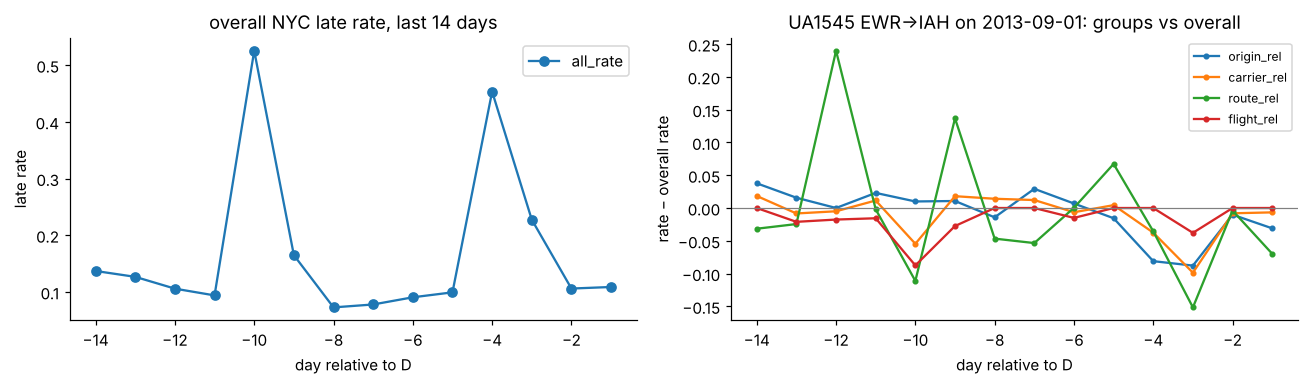

In [6]:
# One flight's two weeks, as the network sees them
i = int(np.argmax((S["valid"]["carrier"] == "UA").to_numpy()))
f = S["valid"].iloc[i]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
days = np.arange(-SEQ_LEN, 0)
for c in ["all_rate"]:
    ax[0].plot(days, seq["valid"][i, :, CH.index(c)], "o-", label=c)
ax[0].set(title="overall NYC late rate, last 14 days", xlabel="day relative to D", ylabel="late rate"); ax[0].legend()
for c in ["origin_rel", "carrier_rel", "route_rel", "flight_rel"]:
    ax[1].plot(days, seq["valid"][i, :, CH.index(c)], "o-", ms=3, label=c)
ax[1].axhline(0, color="grey", lw=.8)
ax[1].set(title=f"{f['carrier']}{f['flight']} {f['origin']}→{f['dest']} on {f['date'].date()}: groups vs overall", xlabel="day relative to D", ylabel="rate − overall rate"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig("reports/figures/06_one_sequence.png"); plt.show()

### The leakage test (technical validation)
A sequence for day D must not change if outcomes **on or after D** change. The test in `tests/test_leakage.py` flips every label from a cut-off day onward and checks that the sequences for the cut-off day are **identical**, and that the sequences for the **next** day do change (so the test can actually fail).

In [7]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_leakage.py"], capture_output=True, text=True)
print(r.stdout[-400:])
LEAK_TESTS_PASSED = r.returncode == 0

...                                                                      [100%]
3 passed in 6.29s



---
## D · Why "relative" history: drift, measured on the inputs
Phase 1's ablation showed boosting got **worse** in October once history features were added, and we blamed **absolute levels**: a rule like "28-day rate > 0.31" learned in a busy summer misfires in a calm autumn. If that is right, an absolute rate should swing with the season, and the same rate **minus the overall rate of the same days** should not.

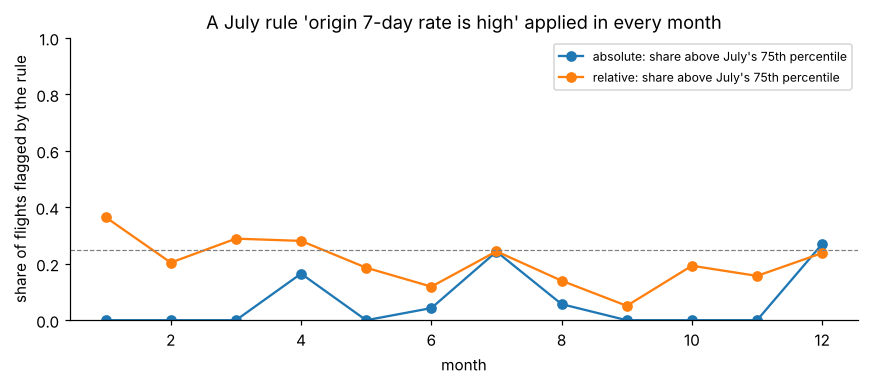

cut-offs learned in July: absolute 0.389, relative +0.026
range of the share across months:
absolute: share above July's 75th percentile    0.270
relative: share above July's 75th percentile    0.314
dtype: float64


month,1,2,3,4,5,6,7,8,9,10,11,12
absolute: share above July's 75th percentile,0.000,0.000,0.000,0.165,0.000,0.043,0.243,0.057,0.000,0.000,0.000,0.270
relative: share above July's 75th percentile,0.365,0.204,0.289,0.281,0.186,0.119,0.244,0.140,0.051,0.193,0.157,0.238


In [8]:
lab = pd.concat([S["train"], S["valid"], S["calib"], S["test"]])
absolute = lab["h_origin_7d_rate"]
relative = lab["h_origin_7d_rate"] - lab["h_all_7d_rate"]
jul = (lab["date"].dt.month == 7).to_numpy()
cut_abs, cut_rel = np.quantile(absolute[jul], 0.75), np.quantile(relative[jul], 0.75)   # a rule a tree could learn in July
drift = pd.DataFrame({
    "absolute: share above July's 75th percentile": (absolute > cut_abs),
    "relative: share above July's 75th percentile": (relative > cut_rel),
    "month": lab["date"].dt.month}).groupby("month").mean().round(3)
fig, ax = plt.subplots(figsize=(8, 3.6))
drift.plot(ax=ax, marker="o"); ax.axhline(0.25, color="grey", lw=.8, ls="--")
ax.set(title="A July rule 'origin 7-day rate is high' applied in every month", ylabel="share of flights flagged by the rule", ylim=(0, 1)); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("reports/figures/06_drift_absolute_vs_relative.png"); plt.show()
spread = (drift.max() - drift.min()).round(3)
print(f"cut-offs learned in July: absolute {cut_abs:.3f}, relative {cut_rel:+.3f}")
print("range of the share across months:"); print(spread)
drift.T

**Reading it:** a rule learned in July ("this origin's 7-day late rate is in the top quarter") barely fires in most other months when it is written on the **absolute** rate: autumn levels are lower everywhere, so almost nothing is "high" by July's standard. Written on the **relative** rate (origin minus all flights over the same 7 days), the same rule keeps firing for a share of flights all year, because it asks "is this origin worse than everyone else right now?", which means the same in July and November. The sequences therefore store **relative** rates, and the overall rate stays as its own channel, so the network can still see "today is a bad day for everyone". Whether this helps the model is tested in notebook 09 (ablation), not assumed here.

In [9]:
out = {"split_sizes": {k: len(v) for k, v in S.items()},
       "n_numeric": len(NUM), "numeric_block_width": int(x_num.shape[1]),
       "categories": cat_table.reset_index().rename(columns={"index": "column"}).to_dict(orient="records"),
       "seq_len": SEQ_LEN, "seq_channels": CH, "n_channels": len(CH), "seq_groups": [n for n, _ in sq.SEQ_GROUPS],
       "seq_alpha": sq.SEQ_ALPHA, "train_seq_mb": round(seq["train"].nbytes / 1e6, 1),
       "leak_tests_passed": bool(LEAK_TESTS_PASSED),
       "drift_monthly": drift.reset_index().to_dict(orient="records"), "drift_range": spread.to_dict(), "july_cuts": {"absolute": float(cut_abs), "relative": float(cut_rel)}, "quick_run": QUICK_RUN}
with open("reports/06_dl_data.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved reports/06_dl_data.json")

saved reports/06_dl_data.json


<details><summary><b>Viva questions for this notebook (click)</b></summary>

1. **What does Phase 2 add to Phase 1?** Learned embeddings for carrier/origin/destination, a model that reads the ordered last 14 days instead of fixed averages, calibrated probabilities and a what-if rescheduling analysis. Label, decision time and split stay the same.
2. **Why z-score inputs for a network but not for XGBoost?** Gradient descent takes steps of the same size in every weight; features on very different scales make some weights move far too fast and others too slowly. Trees only compare a feature with a threshold, so scale does not matter.
3. **What is index 0 / index 1 in the category block?** 0 = never seen in training (a new airport in the test months), 1 = seen fewer than 50 times. Both get their own learned vector instead of crashing or over-fitting a rare category.
4. **Why does the brief say "only if flight history is correctly ordered"?** A temporal model learns from the order of past days; if rows were shuffled or included day D itself, it would learn from the future. Our sequences are indexed by calendar day and end at D−1, and the leakage test proves it.
5. **Why 14 days?** The ACF says yesterday matters most, but one flight number or one aircraft has too few flights per day; 14 days gives small groups enough evidence and covers two weeks of weekday pattern.
6. **Why store rates relative to the overall rate?** Absolute rates drift with the season (section D); the relative rate means the same in July and November. The overall rate stays as its own channel.
7. **How do you know the sequences do not leak?** The unit test flips every label from the cut-off day on: sequences for the cut-off day are identical, and sequences for the next day change.
</details>

In [10]:
#@title 📦 Last step · download the files you must commit { display-mode: "form" }
#@markdown Downloads a zip with your module(s) and results. Also do **File → Download → Download .ipynb** (keeps the outputs).
#@markdown Unzip both into your local clone of the repo and commit them as shown in the team guide.
import glob, zipfile
FILES = [
    'src/fdp/dl_inputs.py',
    'tests/test_leakage.py',
    'reports/06_dl_data.json',
    'reports/figures/06_*.png',
]
paths = sorted({p for pattern in FILES for p in glob.glob(pattern)})
zip_name = "06_outputs.zip"
with zipfile.ZipFile(zip_name, "w") as z:
    for p in paths:
        z.write(p)
print("Packed", len(paths), "files into", zip_name)
for p in paths:
    print("  ", p)
if IN_COLAB:
    from google.colab import files
    files.download(zip_name)

Packed 5 files into 06_outputs.zip
   reports/06_dl_data.json
   reports/figures/06_drift_absolute_vs_relative.png
   reports/figures/06_one_sequence.png
   src/fdp/dl_inputs.py
   tests/test_leakage.py
